In [5]:
%pip install neo4j

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Salwa123_")

In [9]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name,
            friend_name=friend_name
        )

In [10]:
from neo4j import GraphDatabase

def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        records = session.run(
            "MATCH (a:Person)-[:KNOWS]->(friend) "
            "WHERE a.name = $name "
            "RETURN friend.name AS friend_name "
            "ORDER BY friend.name",
            name=name
        )

        for record in records:
            print(record["friend_name"])


with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin



1. Apa nama database yang digunakan pada tutorial ini?
   ```
   database_ = "neo4j"
   ```
2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam satu instance!

// Menampilkan daftar database
SHOW DATABASES;

// Membuat database baru
CREATE DATABASE database_baru;

// Menghapus node Mahasiswa bernama Salwa
MATCH (m:Mahasiswa {nama: 'Salwa'})
DELETE m; 

3. Apa jenis graf pertemanan yang telah dibuat di sini?

   Graf Berarah (Directed Graph)


In [23]:
import os
import pandas as pd

folder = r"D:\SEMESTER 7\Graf Sains Data\UTS"
events_path = os.path.join(folder, "events.csv")

df = pd.read_csv(events_path)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [12]:
import os
import pandas as pd
from tqdm.notebook import tqdm
from neo4j import GraphDatabase

# Lokasi file events.csv
SOURCE = r"D:\SEMESTER 7\Graf Sains Data\UTS"
csv_file_path = os.path.join(SOURCE, "events.csv")

# Koneksi Neo4j
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Salwa123_")

driver = GraphDatabase.driver(URI, auth=AUTH)

# Cek koneksi
driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [15]:
import os
import pandas as pd
from tqdm.auto import tqdm
from neo4j import GraphDatabase

# ==========================================
# 1. KONFIGURASI
# ==========================================

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "Salwa123_")
DATABASE = "neo4j"

SOURCE = r"D:\SEMESTER 7\Graf Sains Data\UTS"
csv_file_path = os.path.join(SOURCE, "events.csv")

batch_size = 1000

# ==========================================
# 2. PERIKSA FILE
# ==========================================

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file_path}"
    )

total_rows = sum(
    1 for _ in open(csv_file_path, encoding="utf-8")
) - 1

total_chunks = (total_rows + batch_size - 1) // batch_size

print("File:", csv_file_path)
print("Total baris:", total_rows)
print("Total batch:", total_chunks)

# ==========================================
# 3. FUNGSI IMPOR
# ==========================================

def import_batch(tx, records):
    query = """
    UNWIND $records AS row
    CREATE (e:Event)
    SET e = row
    """
    tx.run(query, records=records).consume()

# ==========================================
# 4. PROSES IMPOR KE NEO4J
# ==========================================

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")

    with driver.session(database=DATABASE) as session:
        run_write = (
            getattr(session, "execute_write", None)
            or session.write_transaction
        )

        chunks = pd.read_csv(
            csv_file_path,
            chunksize=batch_size
        )

        for chunk in tqdm(
            chunks,
            total=total_chunks,
            desc="Mengimpor data"
        ):
            # Ubah NaN menjadi None agar disimpan sebagai null
            chunk = chunk.astype(object).where(
                pd.notna(chunk), None
            )

            records = chunk.to_dict(orient="records")

            if records:
                run_write(import_batch, records)

print("Proses impor selesai!")

File: D:\SEMESTER 7\Graf Sains Data\UTS\events.csv
Total baris: 2756101
Total batch: 2757
Koneksi Neo4j berhasil!


Mengimpor data:   0%|          | 0/2757 [00:00<?, ?it/s]

Proses impor selesai!


In [16]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

    print("Constraint Visitor dan Item berhasil dibuat.")

In [17]:
def import_batch(tx, records):
    query = """
    UNWIND $records AS data

    MERGE (visitor:Visitor {visitorId: data.visitorid})
    MERGE (item:Item {itemId: data.itemid})

    WITH visitor, item, data

    CALL {
        WITH visitor, item, data
        WITH visitor, item, data
        WHERE data.event = 'view'
        CREATE (visitor)-[:VIEWED {
            timestamp: data.timestamp
        }]->(item)

        UNION ALL

        WITH visitor, item, data
        WITH visitor, item, data
        WHERE data.event = 'addtocart'
        CREATE (visitor)-[:ADDED_TO_CART {
            timestamp: data.timestamp
        }]->(item)

        UNION ALL

        WITH visitor, item, data
        WITH visitor, item, data
        WHERE data.event = 'transaction'
        CREATE (visitor)-[:BOUGHT {
            timestamp: data.timestamp,
            transactionId: data.transactionid
        }]->(item)
    }
    """

    tx.run(query, records=records).consume()

In [21]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
USER = "neo4j"
PASSWORD = "Salwa123_"

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")

    with driver.session(database="neo4j") as db:
        create_constraints(db)

    print("Constraint berhasil diperiksa/dibuat.")

Koneksi Neo4j berhasil!
Constraint Visitor dan Item berhasil dibuat.
Constraint berhasil diperiksa/dibuat.


In [24]:
import os
import pandas as pd
from tqdm.auto import tqdm
from neo4j import GraphDatabase

# Lokasi dataset
SOURCE = r"D:\SEMESTER 7\Graf Sains Data\UTS"
csv_file_path = os.path.join(SOURCE, "events.csv")

# Konfigurasi Neo4j
URI = "neo4j://localhost:7687"
USER = "neo4j"
PASSWORD = "Salwa123_"  # Ganti dengan password asli
DATABASE = "neo4j"  # Sesuaikan dengan database yang tersedia

# Ukuran setiap batch
batch_size = 10_000

# Pastikan file tersedia
if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"File tidak ditemukan: {csv_file_path}")

# Hitung jumlah baris CSV
with open(csv_file_path, "r", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

total_chunks = (total_rows + batch_size - 1) // batch_size

print("File:", csv_file_path)
print("Total baris:", total_rows)
print("Total batch:", total_chunks)

# Proses impor
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")

    with driver.session(database=DATABASE) as session:
        create_constraints(session)

        run_write = (
            getattr(session, "execute_write", None)
            or session.write_transaction
        )

        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor data"):
            # Mengubah nilai kosong menjadi None
            chunk = chunk.astype(object).where(pd.notna(chunk), None)

            records = chunk.to_dict(orient="records")
            run_write(import_batch, records)

print("Proses impor selesai!")

File: D:\SEMESTER 7\Graf Sains Data\UTS\events.csv
Total baris: 2756101
Total batch: 276
Koneksi Neo4j berhasil!
Constraint Visitor dan Item berhasil dibuat.


Mengimpor data:   0%|          | 0/276 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (visitor, item, data) { ... }', position=<SummaryInputPosition line=9, column=5, offset=165>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 165, 'line': 9, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $records AS data\n\n    MERGE (visitor:Visitor {visitorId: data.visitorid})\n    MERGE (item:Item {itemId: data.itemid})\n\n    WITH visitor, item, data\n\n    CALL {\n        WITH visitor, item, data\n        WITH visitor, item, data\n        WHERE data.event = 'view'\n        CREATE (visitor)-[:VIEWED {\n   

Proses impor selesai!


2.1

1. Tentukan 2 periode waktu sebagai filter dari data interaksi.

- **P1 (Data Training):** 20 Mei 2015 sampai 19 Juni 2015.
- **P2 (Data Testing):** 15 Agustus 2015 sampai 14 September 2015.

In [25]:
# 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

import pandas as pd
import os

SOURCE = r"D:\SEMESTER 7\Graf Sains Data\UTS"
csv_file_path = os.path.join(SOURCE, "events.csv")

# Membaca dataset
df = pd.read_csv(csv_file_path)

# Konversi timestamp Unix milidetik ke datetime
df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", errors="coerce"
)

# Filter periode P1: Training
p1 = df[
    (df["datetime"] >= "2015-05-20") &
    (df["datetime"] < "2015-06-20")
].copy()

# Filter periode P2: Testing
p2 = df[
    (df["datetime"] >= "2015-08-15") &
    (df["datetime"] < "2015-09-15")
].copy()

p1["period"] = "P1"
p2["period"] = "P2"

# Menggabungkan hasil filter
filtered_df = pd.concat([p1, p2], ignore_index=True)

# Menyimpan hasil ke CSV
p1.to_csv(os.path.join(SOURCE, "events_P1_training.csv"), index=False)
p2.to_csv(os.path.join(SOURCE, "events_P2_testing.csv"), index=False)
filtered_df.to_csv(os.path.join(SOURCE, "events_filtered.csv"), index=False)

print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))
print("Total data:", len(filtered_df))
print("Data hasil filter berhasil disimpan.")

Jumlah data P1: 633522
Jumlah data P2: 561408
Total data: 1194930
Data hasil filter berhasil disimpan.


In [27]:
# 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah 
# masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

from neo4j import GraphDatabase
import pandas as pd

URI = "neo4j://localhost:7687"
USER = "neo4j"
PASSWORD = "Salwa123_"  # Ganti dengan password Neo4j kamu

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:

        query_nodes = """
        MATCH (n)
        UNWIND labels(n) AS jenis_simpul
        RETURN jenis_simpul, COUNT(*) AS jumlah
        ORDER BY jenis_simpul
        """

        result = session.run(query_nodes)
        df_nodes = pd.DataFrame([record.data() for record in result])

        print("Komposisi Simpul:")
        display(df_nodes)

        query_relations = """
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, COUNT(r) AS jumlah
        ORDER BY jenis_relasi
        """

        result = session.run(query_relations)
        df_relations = pd.DataFrame([record.data() for record in result])

        print("Komposisi Relasi:")
        display(df_relations)

Komposisi Simpul:


,jenis_simpul,jumlah
0,Event,5512202
1,Item,235061
2,Movie,9742
3,Person,4
4,User,610
5,Visitor,1407580


Komposisi Relasi:


,jenis_relasi,jumlah
0,ADDED_TO_CART,69582
1,BOUGHT,22546
2,KNOWS,3
3,RATED,100836
4,VIEWED,2673973


3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

## A. Query Cypher untuk Komposisi Simpul

Query Cypher yang digunakan untuk mengetahui jenis dan jumlah simpul adalah sebagai berikut:

```cypher
MATCH (n)
UNWIND labels(n) AS jenis_simpul
RETURN jenis_simpul, COUNT(*) AS jumlah
ORDER BY jenis_simpul
```

Penjelasan query:

- `MATCH (n)` digunakan untuk mengambil seluruh simpul dalam database.
- `UNWIND labels(n)` digunakan untuk memisahkan label simpul agar setiap jenisnya dapat dihitung.
- `RETURN` menampilkan jenis simpul dan jumlahnya.
- `COUNT(*)` menghitung jumlah simpul untuk setiap label.
- `ORDER BY` mengurutkan hasil berdasarkan jenis simpul.

## B. Hasil Komposisi Simpul

| Jenis Simpul | Jumlah |
|---|---:|
| Event | 5.512.202 |
| Item | 235.061 |
| Movie | 9.742 |
| Person | 4 |
| User | 610 |
| Visitor | 1.407.580 |

Berdasarkan hasil query, simpul `Event` memiliki jumlah terbanyak, yaitu 5.512.202 simpul, sedangkan `Person` memiliki jumlah paling sedikit, yaitu 4 simpul. Simpul `Visitor` merepresentasikan pengunjung dan `Item` merepresentasikan barang dalam dataset. Sementara itu, simpul `Movie`, `User`, dan `Person` juga ditemukan dalam database.

## C. Query Cypher untuk Komposisi Relasi

Query Cypher yang digunakan untuk mengetahui jenis dan jumlah relasi adalah sebagai berikut:

```cypher
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, COUNT(r) AS jumlah
ORDER BY jenis_relasi
```

Penjelasan query:

- `MATCH ()-[r]->()` digunakan untuk mengambil seluruh relasi yang memiliki arah.
- `type(r)` digunakan untuk mendapatkan jenis relasi.
- `COUNT(r)` digunakan untuk menghitung jumlah relasi berdasarkan jenisnya.
- `ORDER BY` digunakan untuk mengurutkan hasil berdasarkan jenis relasi.

## D. Hasil Komposisi Relasi

| Jenis Relasi | Jumlah |
|---|---:|
| ADDED_TO_CART | 69.582 |
| BOUGHT | 22.546 |
| KNOWS | 3 |
| RATED | 100.836 |
| VIEWED | 2.673.973 |

Berdasarkan hasil query, relasi `VIEWED` memiliki jumlah terbanyak, yaitu 2.673.973 relasi. Relasi ini menunjukkan aktivitas pengunjung melihat barang. Relasi `ADDED_TO_CART` menunjukkan aktivitas menambahkan barang ke keranjang, sedangkan `BOUGHT` menunjukkan aktivitas pembelian. Relasi `RATED` dan `KNOWS` juga terdapat dalam database.

## E. Penjelasan Python API

Python API digunakan untuk menghubungkan Python dengan Neo4j melalui `GraphDatabase.driver()`. Perintah `session.run()` digunakan untuk menjalankan query Cypher. Hasil query kemudian diubah menjadi DataFrame menggunakan Pandas agar jumlah setiap jenis simpul dan relasi dapat ditampilkan dalam bentuk tabel.

## F. Kesimpulan

Berdasarkan hasil query, komposisi simpul didominasi oleh `Event`, sedangkan komposisi relasi didominasi oleh `VIEWED`. Hal ini menunjukkan bahwa aktivitas melihat barang merupakan interaksi yang paling banyak tercatat. Ditemukannya simpul `Movie`, `User`, dan `Person`, serta relasi `RATED` dan `KNOWS`, juga menunjukkan bahwa database masih memuat data lain di luar subgraph pengunjung dan barang.

In [29]:
# 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
# karakteristiknya (dimensi, shape, plot networkx, dst.)!

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from neo4j import GraphDatabase
from scipy.sparse import coo_matrix

URI = "neo4j://localhost:7687"
USER = "neo4j"
PASSWORD = "Salwa123_"

# Periode P1: 20 Mei sampai sebelum 20 Juni 2015
start_ts = pd.Timestamp("2015-05-20").value // 10**6
end_ts = pd.Timestamp("2015-06-20").value // 10**6

query = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.timestamp >= $start_ts AND r.timestamp < $end_ts
RETURN
    v.visitorId AS visitor_id,
    i.itemId AS item_id,
    type(r) AS event_type
"""

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(
            query,
            start_ts=start_ts,
            end_ts=end_ts
        )
        df = pd.DataFrame([record.data() for record in result])

# Memeriksa data
print("Jumlah interaksi:", len(df))
display(df.head())

if df.empty:
    raise ValueError(
        "Tidak ada interaksi pada periode P1. "
        "Periksa timestamp dan database."
    )

# Memberikan bobot berdasarkan jenis interaksi
weights = {
    "VIEWED": 1,
    "ADDED_TO_CART": 2,
    "BOUGHT": 3
}
df["weight"] = df["event_type"].map(weights)

# Mengubah ID menjadi indeks matriks
df["user_index"], user_ids = pd.factorize(df["visitor_id"])
df["item_index"], item_ids = pd.factorize(df["item_id"])

# Membentuk VSM User: baris = Visitor, kolom = Item
VSM_User = coo_matrix(
    (
        df["weight"].to_numpy(),
        (
            df["user_index"].to_numpy(),
            df["item_index"].to_numpy()
        )
    ),
    shape=(len(user_ids), len(item_ids))
).tocsr()

print("Dimensi VSM User:", VSM_User.shape)
print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Jumlah nilai nonzero:", VSM_User.nnz)

Jumlah interaksi: 643522


,visitor_id,item_id,event_type
0,257597,355908,VIEWED
1,257597,355908,VIEWED
2,981382,355908,VIEWED
3,979686,355908,VIEWED
4,479732,355908,VIEWED


Dimensi VSM User: (329777, 119627)
Jumlah User: 329777
Jumlah Item: 119627
Jumlah nilai nonzero: 492096


In [ ]:
# 
# Membentuk matriks VSM User
# Setiap User direpresentasikan sebagai vektor rating terhadap seluruh Movie. Nilai 0 berarti tidak ditemukan relasi rating antara User dan Movie tersebut.

# Membuat indeks untuk setiap User dan Movie
user_index = {u: i for i, u in enumerate(users)}
movie_index = {m: i for i, m in enumerate(movies)}

# Mengubah ID simpul menjadi indeks matriks
row = ratings["user_id"].map(user_index).to_numpy()
col = ratings["movie_id"].map(movie_index).to_numpy()
data = ratings["rating"].to_numpy(dtype=float)

# Membentuk matriks User x Movie
X_user = csr_matrix(
    (data, (row, col)),
    shape=(len(users), len(movies))
)

print("Dimensi matriks:", X_user.ndim)
print("Shape VSM User:", X_user.shape)
print("Jumlah nilai bukan nol:", X_user.nnz)
print("Ukuran matriks padat:", X_user.shape[0] * X_user.shape[1])
print("Jumlah elemen tersimpan:", X_user.data.size)

Dimensi matriks: 2
Shape VSM User: (610, 9742)
Jumlah nilai bukan nol: 100836
Ukuran matriks padat: 5942620
Jumlah elemen tersimpan: 100836


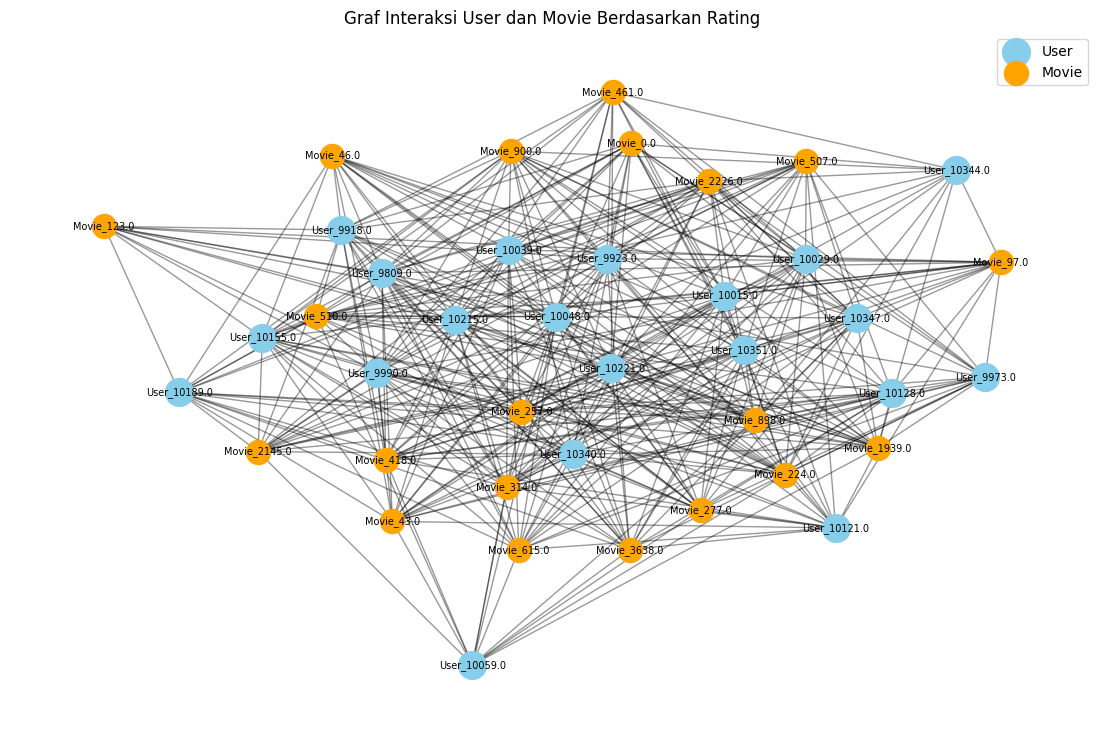

Jumlah simpul pada plot: 40
Jumlah relasi pada plot: 362


In [37]:
# Plot graf menggunakan NetworkX
# Visualisasi menggunakan sampel User dan Movie yang memiliki jumlah rating terbanyak agar graf mudah dibaca.

# Memilih 20 User dengan rating terbanyak
top_users = ratings["user_id"].value_counts().head(20).index

# Memilih 20 Movie dengan rating terbanyak
top_movies = ratings["movie_id"].value_counts().head(20).index

sample = ratings[
    ratings["user_id"].isin(top_users) &
    ratings["movie_id"].isin(top_movies)
].copy()

G = nx.Graph()

for _, r in sample.iterrows():
    user_node = f"User_{r['user_id']}"
    movie_node = f"Movie_{r['movie_id']}"

    G.add_node(user_node, jenis="User")
    G.add_node(movie_node, jenis="Movie")
    G.add_edge(user_node, movie_node, rating=r["rating"])

user_nodes = [
    n for n, d in G.nodes(data=True)
    if d["jenis"] == "User"
]

movie_nodes = [
    n for n, d in G.nodes(data=True)
    if d["jenis"] == "Movie"
]

plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G, pos, nodelist=user_nodes,
    node_color="skyblue", node_size=400,
    label="User"
)

nx.draw_networkx_nodes(
    G, pos, nodelist=movie_nodes,
    node_color="orange", node_size=300,
    label="Movie"
)

nx.draw_networkx_edges(G, pos, alpha=0.4)
nx.draw_networkx_labels(G, pos, font_size=7)

plt.title("Graf Interaksi User dan Movie Berdasarkan Rating")
plt.legend()
plt.axis("off")
plt.show()

print("Jumlah simpul pada plot:", G.number_of_nodes())
print("Jumlah relasi pada plot:", G.number_of_edges())

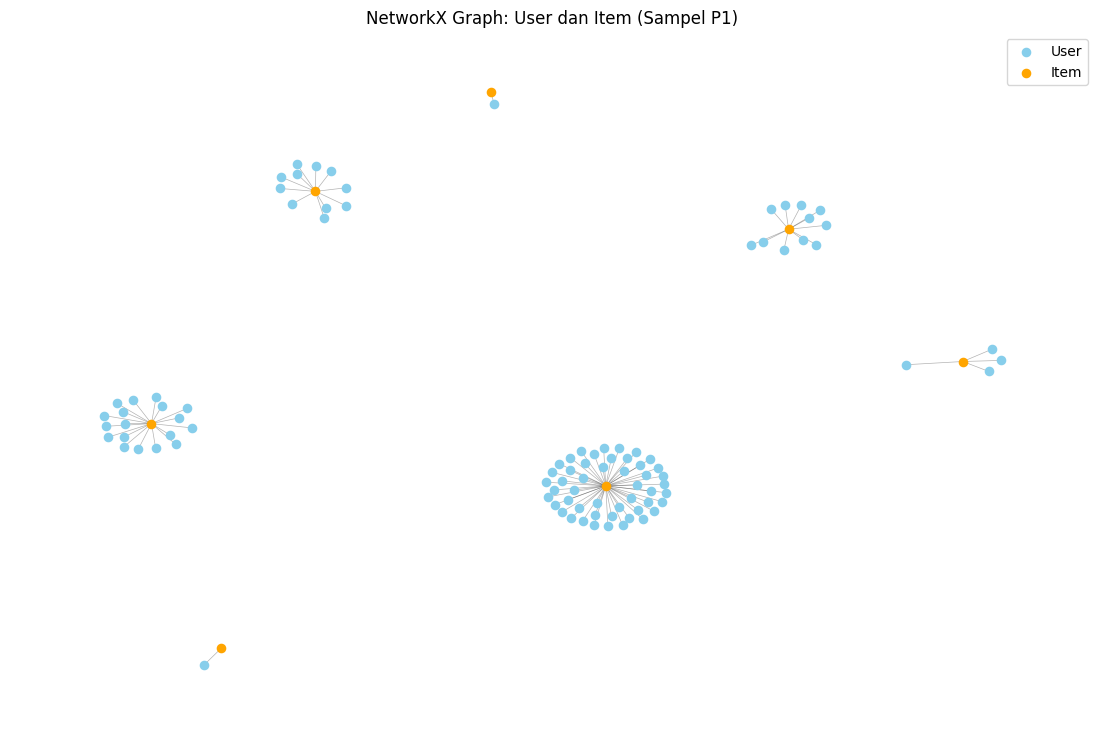

In [31]:
# Mengambil sebagian kecil interaksi agar grafik mudah dibaca
plot_df = df.head(150)

G_user = nx.Graph()

for _, row in plot_df.iterrows():
    user_node = f"Visitor_{row['visitor_id']}"
    item_node = f"Item_{row['item_id']}"

    G_user.add_node(user_node, node_type="User")
    G_user.add_node(item_node, node_type="Item")
    G_user.add_edge(user_node, item_node)

plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G_user, seed=42)

user_nodes = [
    n for n, attr in G_user.nodes(data=True)
    if attr["node_type"] == "User"
]
item_nodes_plot = [
    n for n, attr in G_user.nodes(data=True)
    if attr["node_type"] == "Item"
]

nx.draw_networkx_nodes(
    G_user, pos, nodelist=user_nodes,
    node_color="skyblue", node_size=35, label="User"
)
nx.draw_networkx_nodes(
    G_user, pos, nodelist=item_nodes_plot,
    node_color="orange", node_size=35, label="Item"
)
nx.draw_networkx_edges(G_user, pos, alpha=0.3, width=0.5)

plt.title("NetworkX Graph: User dan Item (Sampel P1)")
plt.legend()
plt.axis("off")
plt.show()

In [32]:
# 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (di-
# mensi, shape, plot networkx, dst.)!

# Membentuk VSM Item dari transpose VSM User
VSM_Item = VSM_User.transpose().tocsr()

print("Dimensi VSM Item:", VSM_Item.shape)
print("Jumlah Item:", VSM_Item.shape[0])
print("Jumlah User:", VSM_Item.shape[1])
print("Jumlah nilai nonzero:", VSM_Item.nnz)

Dimensi VSM Item: (119627, 329777)
Jumlah Item: 119627
Jumlah User: 329777
Jumlah nilai nonzero: 492096


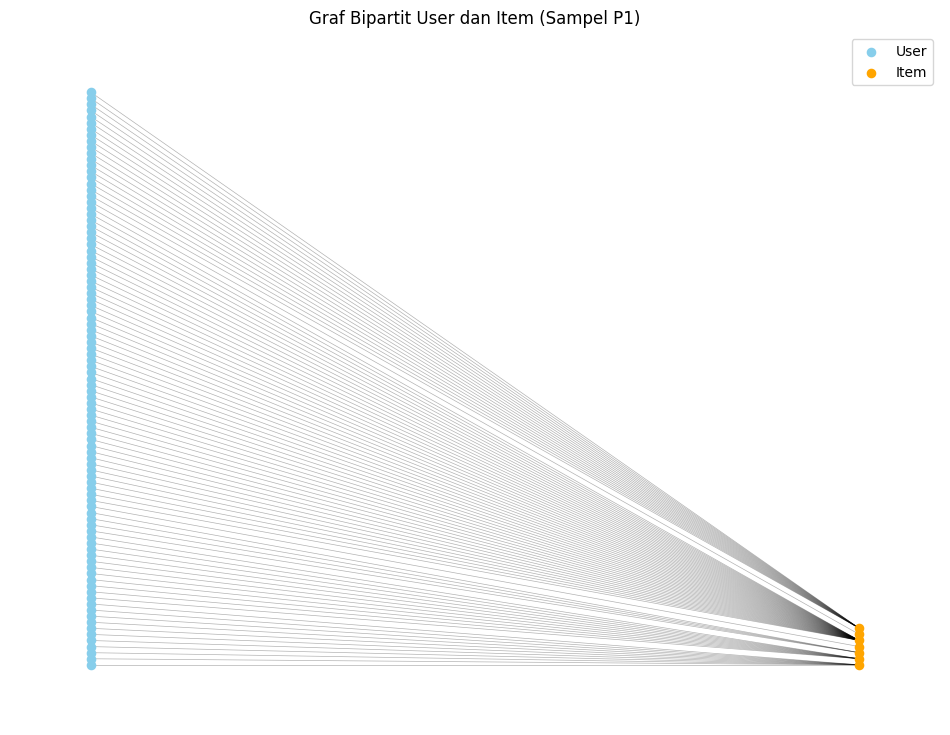

In [33]:
# Membuat graf bipartit dari sampel interaksi
B = nx.Graph()

for _, row in plot_df.iterrows():
    user_node = f"Visitor_{row['visitor_id']}"
    item_node = f"Item_{row['item_id']}"

    B.add_node(user_node, bipartite=0)
    B.add_node(item_node, bipartite=1)
    B.add_edge(user_node, item_node)

left_nodes = [
    n for n, d in B.nodes(data=True) if d["bipartite"] == 0
]
right_nodes = [
    n for n, d in B.nodes(data=True) if d["bipartite"] == 1
]

pos_bipartite = {}

pos_bipartite.update({
    node: (0, i) for i, node in enumerate(left_nodes)
})
pos_bipartite.update({
    node: (1, i) for i, node in enumerate(right_nodes)
})

plt.figure(figsize=(12, 9))
nx.draw_networkx_nodes(
    B, pos_bipartite,
    nodelist=left_nodes,
    node_color="skyblue",
    node_size=35,
    label="User"
)
nx.draw_networkx_nodes(
    B, pos_bipartite,
    nodelist=right_nodes,
    node_color="orange",
    node_size=35,
    label="Item"
)
nx.draw_networkx_edges(
    B, pos_bipartite,
    alpha=0.3,
    width=0.5
)

plt.title("Graf Bipartit User dan Item (Sampel P1)")
plt.legend()
plt.axis("off")
plt.show()

# 4. Vector Space Modelling (VSM) pada Simpul User

# A. Metode

Vector Space Modelling (VSM) dilakukan dengan merepresentasikan aktivitas setiap pengunjung terhadap barang ke dalam bentuk matriks. Pada dataset RetailRocket, simpul `Visitor` diasumsikan sebagai User, sedangkan simpul `Item` merepresentasikan barang.

Data interaksi yang digunakan berasal dari periode P1, yaitu 20 Mei sampai 19 Juni 2015. Jenis interaksi yang digunakan adalah `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Setiap jenis interaksi diberikan bobot masing-masing 1, 2, dan 3.

# B. Karakteristik VSM User

Matriks VSM User memiliki karakteristik sebagai berikut:

- **Baris:** setiap baris merepresentasikan satu User atau Visitor.
- **Kolom:** setiap kolom merepresentasikan satu Item.
- **Nilai matriks:** menunjukkan bobot interaksi User terhadap Item.
- **Dimensi:** jumlah User dikali jumlah Item.
- **Shape:** `(jumlah User, jumlah Item)`.

Matriks menggunakan format sparse agar penyimpanan lebih efisien karena sebagian besar User hanya berinteraksi dengan sebagian kecil Item.

# C. Visualisasi NetworkX

Visualisasi NetworkX menampilkan hubungan antara User dan Item dalam bentuk graf. Simpul berwarna biru merepresentasikan User, sedangkan simpul berwarna oranye merepresentasikan Item. Sisi yang menghubungkan kedua simpul menunjukkan adanya interaksi.

Graf yang ditampilkan merupakan sampel interaksi agar visualisasi lebih mudah dibaca dan tidak terlalu padat.

# 5. Vector Space Modelling (VSM) pada Simpul Item

# A. Metode

VSM Item dibuat dengan membalik orientasi matriks VSM User menggunakan operasi transpose. Dengan demikian, Item menjadi baris dan User menjadi kolom. Nilai matriks tetap menunjukkan bobot interaksi antara Item dan User.

# B. Karakteristik VSM Item

Matriks VSM Item memiliki karakteristik sebagai berikut:

- **Baris:** setiap baris merepresentasikan satu Item.
- **Kolom:** setiap kolom merepresentasikan satu User atau Visitor.
- **Nilai matriks:** menunjukkan bobot interaksi Item terhadap User.
- **Dimensi:** jumlah Item dikali jumlah User.
- **Shape:** `(jumlah Item, jumlah User)`.

VSM Item memiliki jumlah baris dan kolom yang berkebalikan dengan VSM User. Keduanya merepresentasikan data interaksi yang sama, tetapi dilihat dari sudut pandang yang berbeda.

# C. Visualisasi NetworkX

Graf bipartit NetworkX menampilkan User di satu sisi dan Item di sisi lainnya. Hubungan antarsimpul menunjukkan interaksi yang tercatat pada dataset. Visualisasi ini membantu melihat keterhubungan antara pengunjung dan barang.


In [54]:
# 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!
import numpy as np
import pandas as pd
import networkx as nx

# Karakteristik matriks
comparison = pd.DataFrame({
    "Proyeksi": ["User", "Item"],
    "Jumlah Baris": [VSM_User.shape[0], VSM_Item.shape[0]],
    "Jumlah Kolom": [VSM_User.shape[1], VSM_Item.shape[1]],
    "Jumlah Nilai Nonzero": [VSM_User.nnz, VSM_Item.nnz],
    "Ukuran Matriks": [
        VSM_User.shape[0] * VSM_User.shape[1],
        VSM_Item.shape[0] * VSM_Item.shape[1]
    ]
})

comparison["Kepadatan"] = [
    VSM_User.nnz / (VSM_User.shape[0] * VSM_User.shape[1]),
    VSM_Item.nnz / (VSM_Item.shape[0] * VSM_Item.shape[1])
]

display(comparison)

,Proyeksi,Jumlah Baris,Jumlah Kolom,Jumlah Nilai Nonzero,Ukuran Matriks,Kepadatan
0,User,329777,119627,492096,39450233179,0.000012
1,Item,119627,329777,492096,39450233179,0.000012


# 6. Perbandingan Proyeksi User dan Item

Proyeksi User dan Item memiliki kegunaan yang berbeda. Proyeksi User digunakan untuk melihat kemiripan perilaku antar-pengunjung, sedangkan proyeksi Item digunakan untuk melihat kemiripan barang berdasarkan interaksi pengunjung.

| Aspek | Proyeksi User | Proyeksi Item |
|---|---|---|
| Simpul | User atau Visitor | Item |
| Dasar kemiripan | Kesamaan barang yang diinteraksikan | Kesamaan pengunjung yang berinteraksi |
| Tujuan | Menemukan pengunjung dengan perilaku serupa | Menemukan barang yang memiliki pola interaksi serupa |
| Bentuk matriks | User × Item | Item × User |

Dalam penelitian ini, proyeksi Item dipilih karena dapat digunakan untuk mengetahui barang-barang yang memiliki pola interaksi serupa. Hasilnya dapat menjadi dasar rekomendasi barang berdasarkan perilaku pengunjung.

Namun, dari sisi efisiensi komputasi, proyeksi yang lebih baik bergantung pada jumlah User, jumlah Item, dan banyaknya interaksi. Proyeksi Item tidak selalu lebih efisien daripada proyeksi User. Oleh karena itu, pemilihan proyeksi Item pada analisis ini didasarkan pada tujuan untuk mencari kemiripan antar-barang.




Perhitungan selesai dalam 0.69 detik
Jumlah pasangan similarity: 319550
Jumlah Item yang memiliki tetangga: 17953
Jumlah relasi similarity: 86275


,itemA,itemB,score,common
0,355908,97139,0.296838,5
1,355908,238777,0.247540,5
2,355908,259725,0.190941,3
3,355908,393910,0.169031,2
4,355908,419387,0.094491,2
5,248676,76617,0.192629,2
6,248676,29683,0.099494,2
7,367447,443375,0.112004,4
8,367447,18287,0.072326,5
9,367447,88156,0.067090,4


Relasi sebelum penyimpanan:


,jenis_relasi,jumlah
0,VIEWED,2673973
1,RATED,100836
2,ADDED_TO_CART,69582
3,BOUGHT,22546
4,KNOWS,3


Menyimpan SIMILAR_TO:   0%|          | 0/44 [00:00<?, ?it/s]

Relasi setelah penyimpanan:


,jenis_relasi,jumlah
0,VIEWED,2673973
1,RATED,100836
2,SIMILAR_TO,86275
3,ADDED_TO_CART,69582
4,BOUGHT,22546
5,KNOWS,3


Item acuan: 96680
Jumlah Visitor yang berinteraksi: 42


,item_acuan,item_mirip,similarity,visitor_bersama
0,96680,9199,0.207209,7
1,96680,303517,0.115382,3
2,96680,446524,0.111005,3
3,96680,263258,0.106721,3
4,96680,122467,0.098298,3


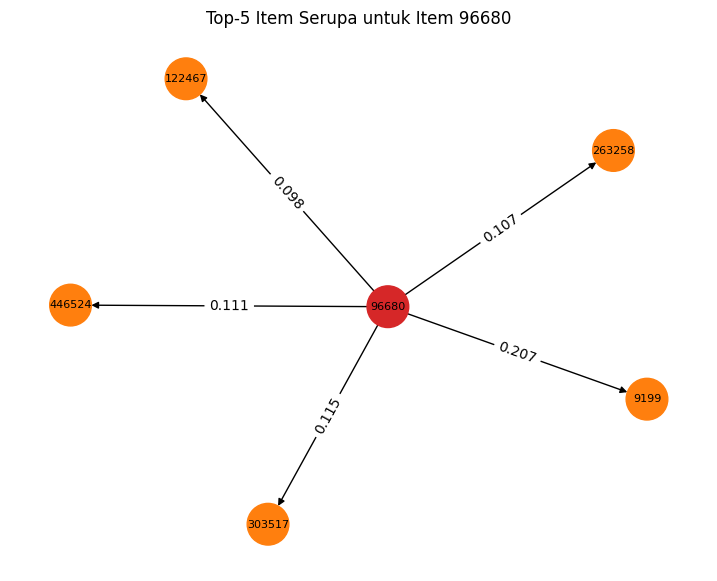

In [37]:
# 7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

import time
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from scipy import sparse as sp
from sklearn.preprocessing import normalize
from neo4j import GraphDatabase
from tqdm.auto import tqdm

# Konfigurasi Neo4j
URI = "neo4j://localhost:7687"
USER = "neo4j"
PASSWORD = "Salwa123_"
DATABASE = "neo4j"

# Parameter similarity
K = 10
MIN_COMMON = 2
SEED = 42
BATCH_SIZE = 2000

# Pastikan VSM dan ID Item sudah tersedia
X = VSM_Item.tocsr()
ids = np.asarray(item_ids)

assert X.shape[0] == len(ids), "Jumlah Item tidak sesuai dengan VSM!"

# Normalisasi vektor Item
start = time.time()

X_norm = normalize(X, norm="l2", axis=1)
S = (X_norm @ X_norm.T).tocsr()

# Menghitung jumlah Visitor bersama untuk setiap pasangan Item
B = X.copy()
B.data = np.ones_like(B.data)
C = (B @ B.T).tocsr()

# Menghilangkan similarity Item dengan dirinya sendiri
S.setdiag(0)
S.eliminate_zeros()

# Hanya mempertahankan pasangan dengan minimal 2 Visitor bersama
mask = C.copy()
mask.data = (mask.data >= MIN_COMMON).astype(np.float32)
mask.eliminate_zeros()

S = S.multiply(mask).tocsr()
S.eliminate_zeros()

print(f"Perhitungan selesai dalam {time.time() - start:.2f} detik")
print("Jumlah pasangan similarity:", S.nnz)

# Mengambil maksimal K tetangga terdekat setiap Item
rows, cols, scores, common_users = [], [], [], []

for i in range(S.shape[0]):
    start_idx, end_idx = S.indptr[i], S.indptr[i + 1]

    if start_idx == end_idx:
        continue

    values = S.data[start_idx:end_idx]
    neighbors = S.indices[start_idx:end_idx]

    k = min(K, len(values))
    chosen = np.argpartition(-values, k - 1)[:k]
    chosen = chosen[np.argsort(-values[chosen])]

    rows.extend([i] * len(chosen))
    cols.extend(neighbors[chosen])
    scores.extend(values[chosen])

    common_users.extend(
        np.asarray(C[i, neighbors[chosen]].toarray()).ravel().astype(int)
    )

# Membuat tabel hasil similarity
df_sim = pd.DataFrame({
    "itemA": ids[np.asarray(rows, dtype=int)],
    "itemB": ids[np.asarray(cols, dtype=int)],
    "score": np.round(scores, 6),
    "common": common_users
})

df_sim.to_csv("similarity_item_topK_P1.csv", index=False)

print("Jumlah Item yang memiliki tetangga:", df_sim["itemA"].nunique())
print("Jumlah relasi similarity:", len(df_sim))
display(df_sim.head(10))

# Menyimpan relasi similarity ke Neo4j
Q_WRITE = """
UNWIND $batch AS row
MATCH (a:Item {itemId: row.itemA})
MATCH (b:Item {itemId: row.itemB})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score,
    s.common = row.common,
    s.method = 'cosine'
"""

def write_batch(tx, records):
    tx.run(Q_WRITE, batch=records).consume()

def run_query(driver, query, **params):
    with driver.session(database=DATABASE) as session:
        return [record.data() for record in session.run(query, **params)]

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    driver.verify_connectivity()

    print("Relasi sebelum penyimpanan:")
    display(pd.DataFrame(run_query(
        driver,
        """
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jumlah DESC
        """
    )))

    with driver.session(database=DATABASE) as session:
        write_tx = (
            getattr(session, "execute_write", None)
            or session.write_transaction
        )

        records = df_sim.to_dict(orient="records")

        for start_idx in tqdm(
            range(0, len(records), BATCH_SIZE),
            desc="Menyimpan SIMILAR_TO"
        ):
            write_tx(
                write_batch,
                records[start_idx:start_idx + BATCH_SIZE]
            )

    print("Relasi setelah penyimpanan:")
    display(pd.DataFrame(run_query(
        driver,
        """
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jumlah DESC
        """
    )))

    # Memilih satu Item acuan yang memiliki cukup banyak interaksi
    degrees = np.diff(X.indptr)
    candidates = np.where(degrees >= 30)[0]

    if len(candidates) == 0:
        candidates = np.where(degrees > 0)[0]

    if len(candidates) == 0:
        raise ValueError("Tidak ada Item dengan interaksi pada VSM.")

    rng = np.random.default_rng(SEED)
    ref_idx = int(rng.choice(candidates))
    ref_item = int(ids[ref_idx])

    print("Item acuan:", ref_item)
    print("Jumlah Visitor yang berinteraksi:", degrees[ref_idx])

    # Mengambil lima Item paling mirip dari Neo4j
    Q_TOP5 = """
    MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
    RETURN a.itemId AS item_acuan,
           b.itemId AS item_mirip,
           s.score AS similarity,
           s.common AS visitor_bersama
    ORDER BY s.score DESC, s.common DESC
    LIMIT 5
    """

    df_top5 = pd.DataFrame(run_query(driver, Q_TOP5, ref=ref_item))
    display(df_top5)

    # Visualisasi NetworkX
    G = nx.DiGraph()
    G.add_node(ref_item)

    for _, row in df_top5.iterrows():
        G.add_edge(
            int(row["item_acuan"]),
            int(row["item_mirip"]),
            weight=float(row["similarity"])
        )

    pos = nx.spring_layout(G, seed=SEED)

    colors = [
        "tab:red" if node == ref_item else "tab:orange"
        for node in G.nodes()
    ]

    plt.figure(figsize=(9, 7))
    nx.draw_networkx(
        G,
        pos,
        with_labels=True,
        node_color=colors,
        node_size=900,
        font_size=8,
        arrows=True
    )

    edge_labels = {
        (u, v): f"{data['weight']:.3f}"
        for u, v, data in G.edges(data=True)
    }
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=edge_labels
    )

    plt.title(f"Top-5 Item Serupa untuk Item {ref_item}")
    plt.axis("off")
    plt.show()

# 7A. CYPHER SQL untuk Mendapatkan 5 Record dengan Similarity Tertinggi

Query Cypher digunakan untuk mencari lima Item yang memiliki nilai similarity tertinggi terhadap Item acuan `96680`.

```cypher
MATCH (a:Item {itemId: 96680})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_mirip,
    r.score AS similarity,
    r.common AS visitor_bersama
ORDER BY similarity DESC
LIMIT 5
```

*Penjelasan:*
- `MATCH` mencari relasi `SIMILAR_TO` dari Item acuan menuju Item lainnya.
- `RETURN` menampilkan ID Item acuan, ID Item mirip, nilai similarity, dan jumlah Visitor bersama.
- `ORDER BY similarity DESC` mengurutkan nilai similarity dari terbesar ke terkecil.
- `LIMIT 5` membatasi hasil menjadi lima record.

# 7B. Menampilkan Nilai Similarity pada Graf yang Telah Ada

Untuk menampilkan nilai similarity pada graf Neo4j, digunakan query berikut.

```cypher
MATCH (a:Item {itemId: 96680})-[r:SIMILAR_TO]->(b:Item)
RETURN a, r, b
ORDER BY r.score DESC
LIMIT 5
```

Query tersebut menampilkan Item acuan, lima Item yang memiliki similarity tertinggi, serta relasi `SIMILAR_TO` yang menghubungkannya. Nilai similarity tersimpan pada properti `score` di setiap relasi.

*Hasil query berdasarkan perhitungan Python:*

| Item acuan | Item mirip | Similarity | Visitor bersama |
|---:|---:|---:|---:|
| 96680 | 9199 | 0,207209 | 7 |
| 96680 | 303517 | 0,115382 | 3 |
| 96680 | 446524 | 0,111005 | 3 |
| 96680 | 263258 | 0,106721 | 3 |
| 96680 | 122467 | 0,098298 | 3 |

*Kesimpulan:*

Berdasarkan hasil perhitungan, Item `9199` memiliki nilai similarity tertinggi terhadap Item acuan `96680`, yaitu sebesar `0,207209`, dengan tujuh Visitor yang berinteraksi dengan kedua Item tersebut. Hasil query pada Neo4j dapat digunakan untuk melihat hubungan antar-Item beserta nilai similarity yang tersimpan pada graf.

JUMLAH RELASI SEBELUM DAN SESUDAH


,jenis_relasi,jumlah_sesudah,jumlah_sebelum
0,ADDED_TO_CART,69582,69582
1,BOUGHT,22546,22546
2,KNOWS,3,3
3,RATED,100836,100836
4,SIMILAR_TO,86275,0
5,VIEWED,2673973,2673973


Total relasi sebelum: 2866940
Total relasi sesudah: 2953215

Lima Item paling mirip: [9199, 303517, 446524, 263258, 122467]

DATA INTERAKSI SEBELUM SIMILARITY
 visitor  item_acuan  item_lain
  134710       96680     446524
  861299       96680     263258
  722990       96680     446524
  618936       96680     263258
  536757       96680     303517
  536757       96680       9199
 1261991       96680     303517
 1261991       96680       9199
 1244122       96680     303517
 1244122       96680       9199
Jumlah pasangan interaksi: 56

RELASI SIMILARITY SESUDAH PERHITUNGAN


,item_acuan,item_mirip,similarity,visitor_bersama
0,96680,9199,0.207209,7
1,96680,303517,0.115382,3
2,96680,446524,0.111005,3
3,96680,263258,0.106721,3
4,96680,122467,0.098298,3


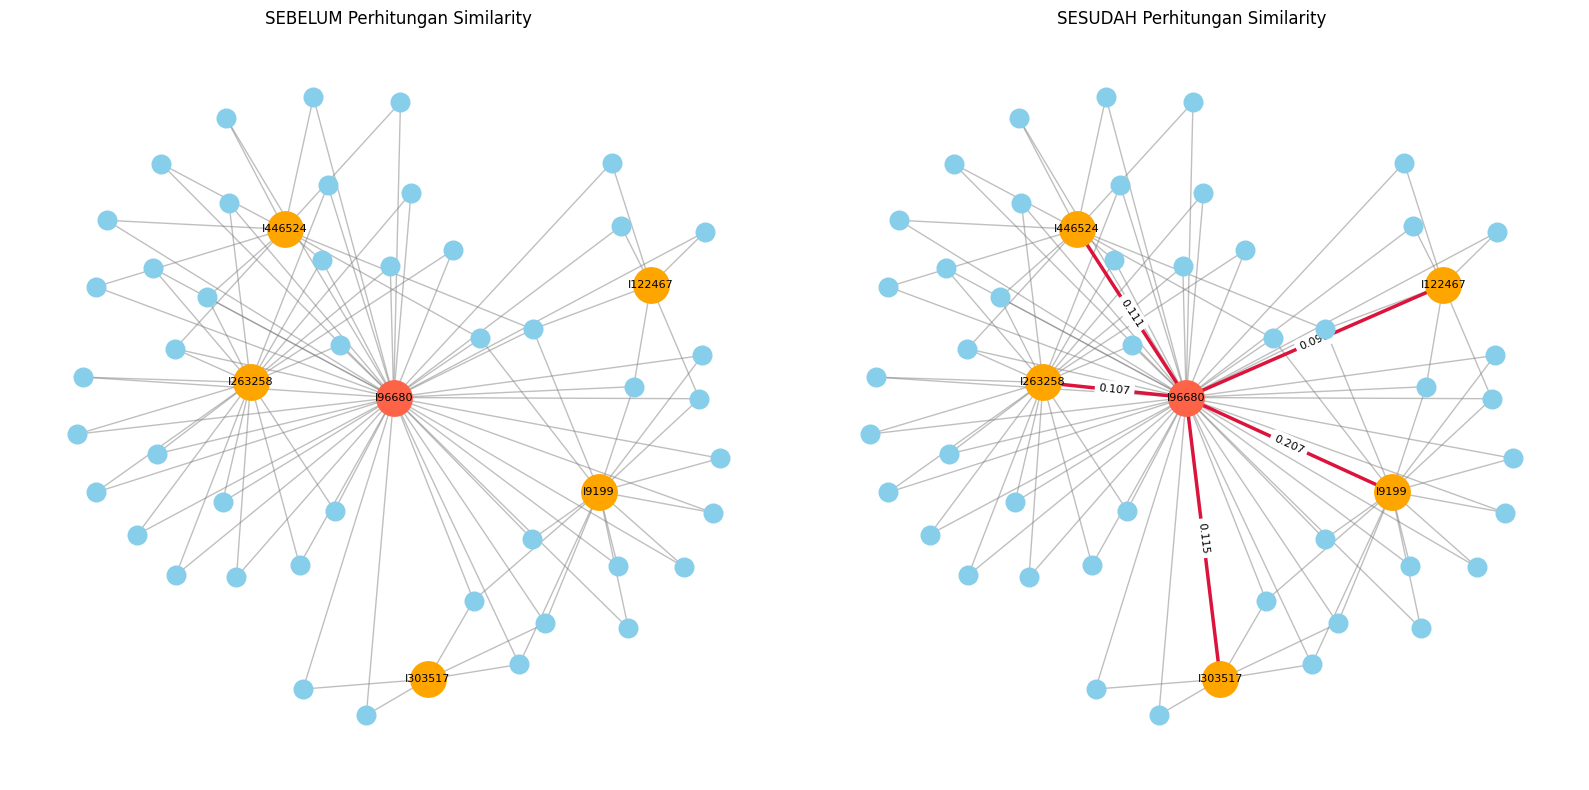

In [41]:
# 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!


import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

# Koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Salwa123_")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def run_query(query, **params):
    with driver.session(database=DATABASE) as session:
        return [record.data() for record in session.run(query, **params)]

# Item acuan sesuai hasil nomor 7
REF_ITEM = 96680

# 1. Membandingkan jumlah relasi sebelum dan sesudah
Q_GLOBAL = """
MATCH ()-[r]->()
WITH type(r) AS jenis_relasi, count(r) AS jumlah_sesudah
RETURN
    jenis_relasi,
    jumlah_sesudah,
    CASE
        WHEN jenis_relasi = 'SIMILAR_TO' THEN 0
        ELSE jumlah_sesudah
    END AS jumlah_sebelum
ORDER BY jenis_relasi
"""

df_global = pd.DataFrame(run_query(Q_GLOBAL))

print("JUMLAH RELASI SEBELUM DAN SESUDAH")
display(df_global)

print("Total relasi sebelum:",
      df_global["jumlah_sebelum"].sum())

print("Total relasi sesudah:",
      df_global["jumlah_sesudah"].sum())

# 2. Mengambil lima Item paling mirip
Q_SIMILAR = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item_mirip
ORDER BY s.score DESC
LIMIT 5
"""

similar_items = [
    row["item_mirip"]
    for row in run_query(Q_SIMILAR, ref=REF_ITEM)
]

print("\nLima Item paling mirip:", similar_items)

# 3. Kondisi sebelum similarity:
# hubungan Visitor dengan Item acuan dan Item yang mirip
Q_BEFORE = """
MATCH (v:Visitor)-[r1:VIEWED|ADDED_TO_CART|BOUGHT]->
      (a:Item {itemId: $ref})
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN $items AND b.itemId <> $ref
RETURN DISTINCT
       v.visitorId AS visitor,
       a.itemId AS item_acuan,
       b.itemId AS item_lain
LIMIT 100
"""

df_before = pd.DataFrame(
    run_query(Q_BEFORE, ref=REF_ITEM, items=similar_items)
)

print("\nDATA INTERAKSI SEBELUM SIMILARITY")
print(df_before.head(10).to_string(index=False))
print("Jumlah pasangan interaksi:", len(df_before))

# 4. Kondisi sesudah similarity:
# mengambil relasi SIMILAR_TO beserta nilainya
Q_AFTER = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       s.score AS similarity,
       s.common AS visitor_bersama
ORDER BY s.score DESC
LIMIT 5
"""

df_after = pd.DataFrame(
    run_query(Q_AFTER, ref=REF_ITEM)
)

print("\nRELASI SIMILARITY SESUDAH PERHITUNGAN")
display(df_after)

# 5. Membuat graf sebelum dan sesudah
def build_graph(tampilkan_similarity):
    G = nx.Graph()

    G.add_node(f"I{REF_ITEM}", jenis="acuan")

    for item in similar_items:
        G.add_node(f"I{item}", jenis="mirip")

    # Hubungan interaksi yang sudah ada sebelum similarity
    for _, row in df_before.iterrows():
        visitor = f"V{row['visitor']}"
        acuan = f"I{row['item_acuan']}"
        item_lain = f"I{row['item_lain']}"

        G.add_node(visitor, jenis="visitor")
        G.add_edge(visitor, acuan, jenis="interaksi")
        G.add_edge(visitor, item_lain, jenis="interaksi")

    # Menambahkan relasi similarity untuk kondisi sesudah
    if tampilkan_similarity:
        for _, row in df_after.iterrows():
            a = f"I{int(row['item_acuan'])}"
            b = f"I{int(row['item_mirip'])}"

            G.add_edge(
                a, b,
                jenis="similarity",
                bobot=float(row["similarity"])
            )

    return G

G_before = build_graph(False)
G_after = build_graph(True)

# Menggunakan posisi node yang sama agar mudah dibandingkan
pos = nx.spring_layout(G_after, seed=42)

def draw_graph(G, ax, judul):
    warna = {
        "visitor": "skyblue",
        "acuan": "tomato",
        "mirip": "orange"
    }

    for jenis, color in warna.items():
        node_list = [
            n for n, data in G.nodes(data=True)
            if data["jenis"] == jenis
        ]

        nx.draw_networkx_nodes(
            G, pos, nodelist=node_list, node_color=color,
            node_size=650 if jenis != "visitor" else 180,
            ax=ax
        )

    # Relasi interaksi Visitor-Item
    edges_interaksi = [
        (u, v) for u, v, d in G.edges(data=True)
        if d["jenis"] == "interaksi"
    ]

    nx.draw_networkx_edges(
        G, pos, edgelist=edges_interaksi,
        edge_color="gray", alpha=0.5, ax=ax
    )

    # Relasi similarity antar-Item
    edges_sim = [
        (u, v) for u, v, d in G.edges(data=True)
        if d["jenis"] == "similarity"
    ]

    nx.draw_networkx_edges(
        G, pos, edgelist=edges_sim,
        edge_color="crimson", width=2.5, ax=ax
    )

    # Label Item
    labels = {
        n: n for n, d in G.nodes(data=True)
        if d["jenis"] != "visitor"
    }

    nx.draw_networkx_labels(
        G, pos, labels=labels, font_size=8, ax=ax
    )

    edge_labels = {
        (u, v): f"{d['bobot']:.3f}"
        for u, v, d in G.edges(data=True)
        if d["jenis"] == "similarity"
    }

    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=edge_labels,
        font_size=8, ax=ax
    )

    ax.set_title(judul)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

draw_graph(
    G_before, axes[0],
    "SEBELUM Perhitungan Similarity"
)

draw_graph(
    G_after, axes[1],
    "SESUDAH Perhitungan Similarity"
)

plt.tight_layout()
plt.show()

driver.close()


# 8. Perbandingan Graf Sebelum dan Sesudah Perhitungan Similarity

# A. Hasil Perbandingan Jumlah Relasi

Berdasarkan hasil query Neo4j, diperoleh perbandingan jumlah relasi sebelum dan sesudah perhitungan similarity sebagai berikut.

| Jenis Relasi | Sebelum | Sesudah |
|---|---:|---:|
| `ADDED_TO_CART` | 69.582 | 69.582 |
| `BOUGHT` | 22.546 | 22.546 |
| `KNOWS` | 3 | 3 |
| `RATED` | 100.836 | 100.836 |
| `SIMILAR_TO` | 0 | 86.275 |
| `VIEWED` | 2.673.973 | 2.673.973 |
| **Total** | **2.866.940** | **2.953.215** |

Sebelum perhitungan similarity, graf memiliki 2.866.940 relasi. Setelah perhitungan, terdapat tambahan 86.275 relasi `SIMILAR_TO`, sehingga total relasi menjadi 2.953.215. Jumlah relasi lainnya tetap sama.

# B. Graf Sebelum Perhitungan Similarity

Sebelum perhitungan similarity, graf memperlihatkan hubungan interaksi Visitor terhadap Item acuan `96680` dan Item lainnya. Berdasarkan hasil query, ditemukan 56 pasangan interaksi yang melibatkan lima Item dengan nilai similarity tertinggi.

Contoh hasil query:

| Visitor | Item Acuan | Item Lain |
|---:|---:|---:|
| 134710 | 96680 | 446524 |
| 861299 | 96680 | 263258 |
| 722990 | 96680 | 446524 |
| 536757 | 96680 | 303517 |
| 536757 | 96680 | 9199 |

Pada kondisi ini, graf menunjukkan hubungan interaksi antara Visitor dan Item tanpa relasi kemiripan antar-Item.

**Gambar 8.1 Graf Sebelum Perhitungan Similarity**

*Masukkan screenshot graf `G_before` di bagian ini.*

# C. Graf Sesudah Perhitungan Similarity

Setelah perhitungan similarity, graf memiliki tambahan relasi `SIMILAR_TO` yang menghubungkan Item berdasarkan kemiripan pola interaksi Visitor.

Berikut lima Item dengan nilai similarity tertinggi terhadap Item acuan `96680`.

| Item Acuan | Item Mirip | Similarity | Visitor Bersama |
|---:|---:|---:|---:|
| 96680 | 9199 | 0,207209 | 7 |
| 96680 | 303517 | 0,115382 | 3 |
| 96680 | 446524 | 0,111005 | 3 |
| 96680 | 263258 | 0,106721 | 3 |
| 96680 | 122467 | 0,098298 | 3 |

Item `9199` memiliki nilai similarity tertinggi terhadap Item `96680`, yaitu 0,207209, dengan tujuh Visitor yang berinteraksi dengan kedua Item tersebut.

**Gambar 8.2 Graf Sesudah Perhitungan Similarity**

*Masukkan screenshot graf `G_after` di bagian ini.*

# D. Kesimpulan

Perhitungan similarity menambahkan informasi kemiripan antar-Item ke dalam graf. Sebelum perhitungan, graf menunjukkan hubungan interaksi Visitor terhadap Item. Sesudah perhitungan, graf juga menampilkan relasi `SIMILAR_TO` beserta nilai similarity. Jumlah relasi meningkat dari 2.866.940 menjadi 2.953.215.

2.2

In [ ]:
# 1A dan 1B

import os
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.preprocessing import normalize
import math

# ==========================================
# 1. KONFIGURASI DATA
# ==========================================
SOURCE = r"D:\SEMESTER 7\Graf Sains Data\UTS"

K = 5
N_REKOMENDASI = 3
TOP_EVALUASI = 5
SEED = 42

EVENT_RELEVAN = ["view", "addtocart", "transaction"]

# ==========================================
# 2. MENGGUNAKAN DATA VSM YANG SUDAH ADA
# ==========================================

R = VSM_User.tocsr()

user_ids = np.asarray(user_ids)
item_ids = np.asarray(item_ids)

df_sim = pd.read_csv(
    os.path.join(SOURCE, "similarity_item_topK_P1.csv")
)

assert R.shape == (len(user_ids), len(item_ids)), \
    "Dimensi matriks tidak sesuai dengan ID Visitor dan Item."

df_sim["itemA"] = df_sim["itemA"].astype(int)
df_sim["itemB"] = df_sim["itemB"].astype(int)

print("Matriks VSM:", R.shape)
print("Jumlah Visitor:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Data similarity berhasil dimuat:", len(df_sim))

# ==========================================
# 3. MENYUSUN TETANGGA SETIAP ITEM
# ==========================================
df_sim = df_sim.sort_values(
    ["itemA", "score", "itemB"],
    ascending=[True, False, True]
)

tetangga_item = {}

for row in df_sim.itertuples(index=False):
    asal = int(row.itemA)
    tujuan = int(row.itemB)
    nilai = float(row.score)

    daftar = tetangga_item.setdefault(asal, [])

    if len(daftar) < K:
        daftar.append((tujuan, nilai))

print("Jumlah Item yang memiliki tetangga:", len(tetangga_item))

# ==========================================
# 4. FUNGSI MENGAMBIL RIWAYAT VISITOR
# ==========================================
def ambil_riwayat(index_user):
    baris = R.getrow(index_user)
    hasil = []

    for index_item, bobot in zip(baris.indices, baris.data):
        hasil.append(
            (int(item_ids[index_item]), float(bobot))
        )

    return hasil


# ==========================================
# 5. FUNGSI REKOMENDASI KNN
# ==========================================
def rekomendasikan(riwayat, k=K, jumlah=5):
    item_dilihat = {item for item, _ in riwayat}
    skor_item = {}

    for item, bobot in riwayat:
        kandidat = tetangga_item.get(item, [])[:k]

        for item_tetangga, similarity in kandidat:
            if item_tetangga in item_dilihat:
                continue

            kontribusi = bobot * similarity

            skor_item[item_tetangga] = (
                skor_item.get(item_tetangga, 0.0)
                + kontribusi
            )

    urutan = sorted(
        skor_item.items(),
        key=lambda pasangan: (-pasangan[1], pasangan[0])
    )

    return urutan[:jumlah]

# ==========================================
# 6. MENYIAPKAN DATA P2 UNTUK EVALUASI
# ==========================================

file_p2 = os.path.join(SOURCE, "events_P2_testing.csv")
file_semua = os.path.join(SOURCE, "events.csv")

if os.path.exists(file_p2):
    p2 = pd.read_csv(
        file_p2,
        usecols=["visitorid", "itemid", "event"]
    )

elif os.path.exists(file_semua):
    p2 = pd.read_csv(
        file_semua,
        usecols=["visitorid", "itemid", "event", "timestamp"]
    )

    # Timestamp RetailRocket menggunakan milidetik
    waktu = pd.to_datetime(
        p2["timestamp"],
        unit="ms",
        utc=True
    )

    mulai_p2 = pd.Timestamp("2015-08-15", tz="UTC")
    akhir_p2 = pd.Timestamp("2015-09-15", tz="UTC")

    p2 = p2.loc[
        (waktu >= mulai_p2) & (waktu < akhir_p2),
        ["visitorid", "itemid", "event"]
    ].copy()

else:
    raise FileNotFoundError(
        "File events_P2_testing.csv dan events.csv "
        "tidak ditemukan di folder SOURCE."
    )

p2 = p2[p2["event"].isin(EVENT_RELEVAN)].copy()

p2["visitorid"] = pd.to_numeric(
    p2["visitorid"], errors="coerce"
)
p2["itemid"] = pd.to_numeric(
    p2["itemid"], errors="coerce"
)

p2 = p2.dropna(subset=["visitorid", "itemid"])
p2["visitorid"] = p2["visitorid"].astype(int)
p2["itemid"] = p2["itemid"].astype(int)

item_relevan = p2.groupby("visitorid")["itemid"].agg(set)

print("Jumlah interaksi relevan di P2:", len(p2))
print("Jumlah Visitor di P2:", len(item_relevan))


# ==========================================
# 7. FUNGSI EVALUASI REKOMENDASI
# ==========================================
def hit_at_k(hasil, relevan, k=5):
    return int(
        any(item in relevan for item, _ in hasil[:k])
    )


def dcg(nilai_relevansi):
    return sum(
        nilai / math.log2(posisi + 2)
        for posisi, nilai in enumerate(nilai_relevansi)
    )


def ndcg_at_k(hasil, relevan, k=5):
    relevansi = [
        1 if item in relevan else 0
        for item, _ in hasil[:k]
    ]

    dcg_aktual = dcg(relevansi)
    dcg_ideal = dcg(
        [1] * min(len(relevan), k)
    )

    return dcg_aktual / dcg_ideal if dcg_ideal > 0 else 0.0


# ==========================================
# 8. MENENTUKAN VISITOR YANG DAPAT DIEVALUASI
# ==========================================
posisi_user = {
    int(visitor): idx
    for idx, visitor in enumerate(user_ids)
}

user_bersama = sorted(
    set(posisi_user).intersection(item_relevan.keys())
)

data_evaluasi = []

for visitor in user_bersama:
    idx = posisi_user[visitor]
    riwayat = ambil_riwayat(idx)

    sudah_ada = {item for item, _ in riwayat}
    relevan_baru = item_relevan[visitor] - sudah_ada

    if not relevan_baru:
        continue

    hasil = rekomendasikan(riwayat, k=K, jumlah=TOP_EVALUASI)

    if len(hasil) < N_REKOMENDASI:
        continue

    data_evaluasi.append({
        "visitorid": visitor,
        "jumlah_riwayat": len(riwayat),
        "jumlah_relevan": len(relevan_baru),
        "hit5": hit_at_k(hasil, relevan_baru, TOP_EVALUASI),
        "ndcg5": ndcg_at_k(hasil, relevan_baru, TOP_EVALUASI)
    })

df_eval = pd.DataFrame(data_evaluasi)

print("\nJumlah Visitor P1 dan P2:", len(user_bersama))
print("Visitor yang dapat dievaluasi:", len(df_eval))

if df_eval.empty:
    raise ValueError(
        "Tidak ada Visitor yang memenuhi syarat evaluasi. "
        "Periksa kecocokan ID Visitor, data P2, dan matriks VSM."
    )

print(
    "Rata-rata Hit@5:",
    round(df_eval["hit5"].mean(), 4)
)
print(
    "Rata-rata NDCG@5:",
    round(df_eval["ndcg5"].mean(), 4)
)


# ==========================================
# 9. MEMILIH SATU VISITOR SECARA ACAK
# ==========================================
rng = np.random.default_rng(SEED)

populasi = np.sort(df_eval["visitorid"].to_numpy())
visitor_pilihan = int(rng.choice(populasi))

index_pilihan = posisi_user[visitor_pilihan]
riwayat_pilihan = ambil_riwayat(index_pilihan)

print("\nSeed pemilihan:", SEED)
print("Jumlah kandidat Visitor:", len(populasi))
print("Visitor terpilih:", visitor_pilihan)
print("Jumlah Item dalam riwayat:", len(riwayat_pilihan))


# ==========================================
# 10. BAGIAN (1a): MENAMPILKAN 5 TETANGGA KNN
# ==========================================
daftar_tetangga = []

for item, bobot in riwayat_pilihan:
    for item_lain, similarity in tetangga_item.get(item, [])[:K]:
        daftar_tetangga.append({
            "item_riwayat": item,
            "item_tetangga": item_lain,
            "similarity": similarity,
            "bobot_riwayat": bobot
        })

df_tetangga = pd.DataFrame(daftar_tetangga)

print("\nContoh tetangga Item dari riwayat Visitor:")
if not df_tetangga.empty:
    display(df_tetangga.head(10))
else:
    print("Tidak ditemukan tetangga untuk riwayat Visitor ini.")

hasil_ranking = rekomendasikan(
    riwayat_pilihan,
    k=K,
    jumlah=TOP_EVALUASI
)

df_ranking = pd.DataFrame(
    hasil_ranking,
    columns=["itemId", "skor_rekomendasi"]
)

df_ranking.insert(
    0, "peringkat", range(1, len(df_ranking) + 1)
)

print("\nRanking rekomendasi:")
display(df_ranking)


# ==========================================
# 11. BAGIAN (1b): MEMILIH 3 ITEM IKLAN
# ==========================================
df_iklan = df_ranking.head(5).copy()

print(
    f"\nLima item yang direkomendasikan untuk Visitor "
    f"{visitor_pilihan}, dengan K={K}:"
)

display(df_iklan)

print(
    "ID Item rekomendasi:",
    df_iklan["itemId"].astype(int).tolist()
)

Matriks VSM: (329777, 119627)
Jumlah Visitor: 329777
Jumlah Item: 119627
Data similarity berhasil dimuat: 86275
Jumlah Item yang memiliki tetangga: 17953
Jumlah interaksi relevan di P2: 561408
Jumlah Visitor di P2: 314804

Jumlah Visitor P1 dan P2: 6678
Visitor yang dapat dievaluasi: 2707
Rata-rata Hit@5: 0.017
Rata-rata NDCG@5: 0.0072

Seed pemilihan: 42
Jumlah kandidat Visitor: 2707
Visitor terpilih: 127311
Jumlah Item dalam riwayat: 5

Contoh tetangga Item dari riwayat Visitor:


,item_riwayat,item_tetangga,similarity,bobot_riwayat
0,39070,432861,0.358746,1.0
1,39070,167653,0.122902,1.0
2,39070,399748,0.089453,1.0
3,39070,191807,0.073855,1.0
4,39070,290993,0.049635,1.0
5,54805,108936,0.268124,1.0



Ranking rekomendasi:


,peringkat,itemId,skor_rekomendasi
0,1,432861,0.358746
1,2,108936,0.268124
2,3,167653,0.122902
3,4,399748,0.089453
4,5,191807,0.073855



Lima item yang direkomendasikan untuk Visitor 127311, dengan K=5:


,peringkat,itemId,skor_rekomendasi
0,1,432861,0.358746
1,2,108936,0.268124
2,3,167653,0.122902
3,4,399748,0.089453
4,5,191807,0.073855


ID Item rekomendasi: [432861, 108936, 167653, 399748, 191807]


# 1a. Tahapan dan Analisis Rekomendasi KNN

Metode *K-Nearest Neighbors* (KNN) digunakan untuk merekomendasikan item berdasarkan kemiripan antaritem (*Item-Item Similarity*). Nilai kemiripan dihitung menggunakan *cosine similarity* dari matriks VSM periode P1.

Tahapan rekomendasi yang dilakukan adalah sebagai berikut.

1. Mengambil riwayat interaksi Visitor pada periode P1 beserta bobotnya dari matriks VSM.
2. Mencari maksimal lima tetangga terdekat (\(K=5\)) untuk setiap item dalam riwayat Visitor berdasarkan nilai *cosine similarity*.
3. Menghitung skor kandidat dengan menjumlahkan hasil perkalian bobot interaksi setiap item dalam riwayat dengan nilai kemiripan item tetangganya.
4. Menghapus kandidat yang sudah ada dalam riwayat Visitor, kemudian mengurutkan kandidat berdasarkan skor tertinggi. Jika skornya sama, pengurutan dilakukan berdasarkan ID item terkecil agar hasil konsisten.
5. Mengambil lima item teratas untuk evaluasi dan tiga item teratas sebagai rekomendasi iklan.

Pemilihan Visitor dilakukan secara acak menggunakan `SEED = 42` agar hasilnya dapat direproduksi selama daftar kandidat dan urutannya tetap sama. Dari 2.707 Visitor yang memenuhi syarat evaluasi, terpilih Visitor ID **127311**, dengan riwayat interaksi sebanyak 5 item.

Hasil evaluasi menghasilkan rata-rata **Hit@5 sebesar 0,017** dan **NDCG@5 sebesar 0,0072**. Nilai tersebut menunjukkan bahwa item yang relevan pada periode P2 relatif jarang muncul pada lima rekomendasi teratas.


# 1b. Lima Item yang Direkomendasikan untuk K = 5

Berdasarkan hasil perhitungan KNN pada Visitor ID 127311 dengan \(K=5\), diperoleh lima item dengan skor rekomendasi tertinggi sebagai berikut.

| Peringkat | ID Item | Skor Rekomendasi |
|---:|---:|---:|
| 1 | 432861 | 0,358746 |
| 2 | 108936 | 0,268124 |
| 3 | 167653 | 0,122902 |
| 4 | 399748 | 0,089453 |
| 5 | 191807 | 0,073855 |

Item **432861** menempati peringkat pertama karena memiliki skor rekomendasi tertinggi, yaitu 0,358746. Selanjutnya, item 108936 berada di peringkat kedua dengan skor 0,268124, diikuti item 167653, 399748, dan 191807.

Dari lima item tersebut, **tiga item dengan peringkat tertinggi dipilih sebagai rekomendasi iklan utama**, yaitu item 432861, 108936, dan 167653. Ketiganya dipilih karena memiliki skor rekomendasi tertinggi dibandingkan dua item lainnya.

In [52]:

# ==========================================
# SOAL 2: HIT@5 DAN NDCG@5
# ==========================================

# 1. Menentukan item yang sudah ada dalam riwayat Visitor
item_riwayat = {
    item for item, bobot in riwayat_pilihan
}

# Mengambil item yang diakses Visitor pada periode P2
item_p2_visitor = item_relevan.get(visitor_pilihan, set())

# Menghapus item yang sudah ada pada riwayat P1
item_relevan_baru = item_p2_visitor - item_riwayat

print("Visitor ID:", visitor_pilihan)
print("Item relevan baru pada P2:", sorted(item_relevan_baru))


# 2. Mengambil lima item rekomendasi teratas
top5 = df_ranking.head(5).copy()

# Memberi nilai 1 jika item relevan, dan 0 jika tidak relevan
top5["relevansi"] = top5["itemId"].apply(
    lambda item: int(item in item_relevan_baru)
)

print("\n=== LIMA ITEM REKOMENDASI ===")
print(top5.to_string(index=False))


# 3. Memilih tiga item teratas sebagai iklan utama
top3_iklan = top5.head(3).copy()

print("\n=== TIGA ITEM TERATAS YANG DIPILIH SEBAGAI IKLAN ===")
print(top3_iklan.to_string(index=False))

print(
    "\nID item iklan utama:",
    top3_iklan["itemId"].astype(int).tolist()
)


# 4. Menghitung Hit@5
jumlah_hit = top5["relevansi"].sum()
hit5 = int(jumlah_hit > 0)


# 5. Menghitung DCG@5 dan IDCG@5
rel = top5["relevansi"].tolist()

dcg5 = dcg(rel)
idcg5 = dcg([1] * min(len(item_relevan_baru), 5))


# 6. Menghitung NDCG@5
ndcg5 = dcg5 / idcg5 if idcg5 > 0 else 0.0


# 7. Menampilkan hasil evaluasi
print("\n=== HASIL EVALUASI ===")
print(f"Hit@5  = {hit5}")
print(f"DCG@5  = {dcg5:.4f}")
print(f"IDCG@5 = {idcg5:.4f}")
print(f"NDCG@5 = {ndcg5:.4f}")


Visitor ID: 127311
Item relevan baru pada P2: [16206, 49446, 205275]

=== LIMA ITEM REKOMENDASI ===
 peringkat  itemId  skor_rekomendasi  relevansi
         1  432861          0.358746          0
         2  108936          0.268124          0
         3  167653          0.122902          0
         4  399748          0.089453          0
         5  191807          0.073855          0

=== TIGA ITEM TERATAS YANG DIPILIH SEBAGAI IKLAN ===
 peringkat  itemId  skor_rekomendasi  relevansi
         1  432861          0.358746          0
         2  108936          0.268124          0
         3  167653          0.122902          0

ID item iklan utama: [432861, 108936, 167653]

=== HASIL EVALUASI ===
Hit@5  = 0
DCG@5  = 0.0000
IDCG@5 = 2.1309
NDCG@5 = 0.0000


# Analisis Hasil Evaluasi Hit@5 dan NDCG@5

Berdasarkan hasil pengujian pada Visitor ID 127311, diperoleh tiga item relevan baru pada periode P2, yaitu item 16206, 49446, dan 205275. Namun, lima item rekomendasi yang dihasilkan oleh metode KNN adalah 432861, 108936, 167653, 399748, dan 191807. Tidak ada item rekomendasi yang sesuai dengan item relevan tersebut.

Hasil evaluasi menunjukkan nilai **Hit@5 = 0**, yang berarti tidak terdapat item relevan dalam lima rekomendasi teratas. Nilai **DCG@5 = 0,0000** menunjukkan bahwa tidak ada item relevan yang berhasil ditempatkan dalam daftar rekomendasi. Sementara itu, **IDCG@5 = 2,1309** merupakan nilai DCG ideal apabila ketiga item relevan berada pada posisi teratas. Dengan demikian, nilai **NDCG@5 = 0,0000** menunjukkan bahwa hasil rekomendasi untuk Visitor tersebut belum sesuai dengan item yang diakses pada periode P2.

Dari lima item yang direkomendasikan, tiga item dengan skor tertinggi, yaitu 432861, 108936, dan 167653, dipilih sebagai iklan utama. Namun, ketiganya juga tidak termasuk dalam item relevan baru. Hal ini menunjukkan bahwa pada pengujian terhadap Visitor 127311, metode KNN belum mampu menghasilkan rekomendasi yang sesuai dengan interaksi pengguna pada periode berikutnya. Hasil ini hanya menggambarkan performa pada satu Visitor sehingga tidak dapat langsung digunakan untuk menyimpulkan performa model secara keseluruhan.